# 01 — Exploratory Data Analysis

**Project:** Jakarta House Price Predictor
**Dataset:** [Jakarta House Price Dataset](https://www.kaggle.com/datasets/abiyyurasyiq/jakarta-house-price-dataset) (MIT)
**Scope:** 5 administrative cities of DKI Jakarta only — not Jabodetabek
**Unit:** one property listing
**Target:** listing price in IDR (Rupiah)

This notebook audits the raw data, documents data-quality issues, visualizes the main
patterns, and records every cleaning decision implemented in `src/data_prep.py`.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "pyproject.toml").exists():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Project root not found")
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_PATH = PROJECT_ROOT / "data" / "raw" / "jakarta_house.csv"
CLEAN_PATH = PROJECT_ROOT / "data" / "processed" / "train_clean.csv"
REPORT_PATH = PROJECT_ROOT / "results" / "cleaning_report.json"
FIG_DIR = PROJECT_ROOT / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 150

raw = pd.read_csv(RAW_PATH)
clean = pd.read_csv(CLEAN_PATH)
report = json.loads(REPORT_PATH.read_text())

print(f"raw:   {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print(f"clean: {clean.shape[0]:,} rows x {clean.shape[1]} columns")

raw:   10,000 rows x 9 columns
clean: 9,401 rows x 9 columns


## 1. Structure and data quality

In [2]:
summary = pd.DataFrame(
    {
        "dtype": raw.dtypes.astype(str),
        "missing": raw.isna().sum(),
        "unique": raw.nunique(),
        "example": raw.iloc[0],
    }
)
display(summary)

,dtype,missing,unique,example
index,int64,0,10000,1
price,int64,0,774,5900000000
district,str,0,253,Citra Garden
city,str,0,5,Jakarta Barat
bed_rooms,int64,0,47,2
bath_rooms,int64,0,45,4
carport,int64,0,19,2
land_area,float64,3,1014,250.0
building_area,float64,5,678,350.0


In [3]:
duplicate_columns = [c for c in raw.columns if c != "index"]
print("Full duplicate rows:              ", int(raw.duplicated().sum()))
print("Duplicates excluding index:       ", int(raw.duplicated(subset=duplicate_columns).sum()))
print("Rows inside duplicate groups:     ", int(raw.duplicated(subset=duplicate_columns, keep=False).sum()))
print("Index is unique:                  ", bool(raw["index"].is_unique))
print("Cities:                           ", raw["city"].nunique())
print("Districts:                        ", raw["district"].nunique())

Full duplicate rows:               0
Duplicates excluding index:        526
Rows inside duplicate groups:      951
Index is unique:                   True
Cities:                            5
Districts:                         253


## 2. Target distribution

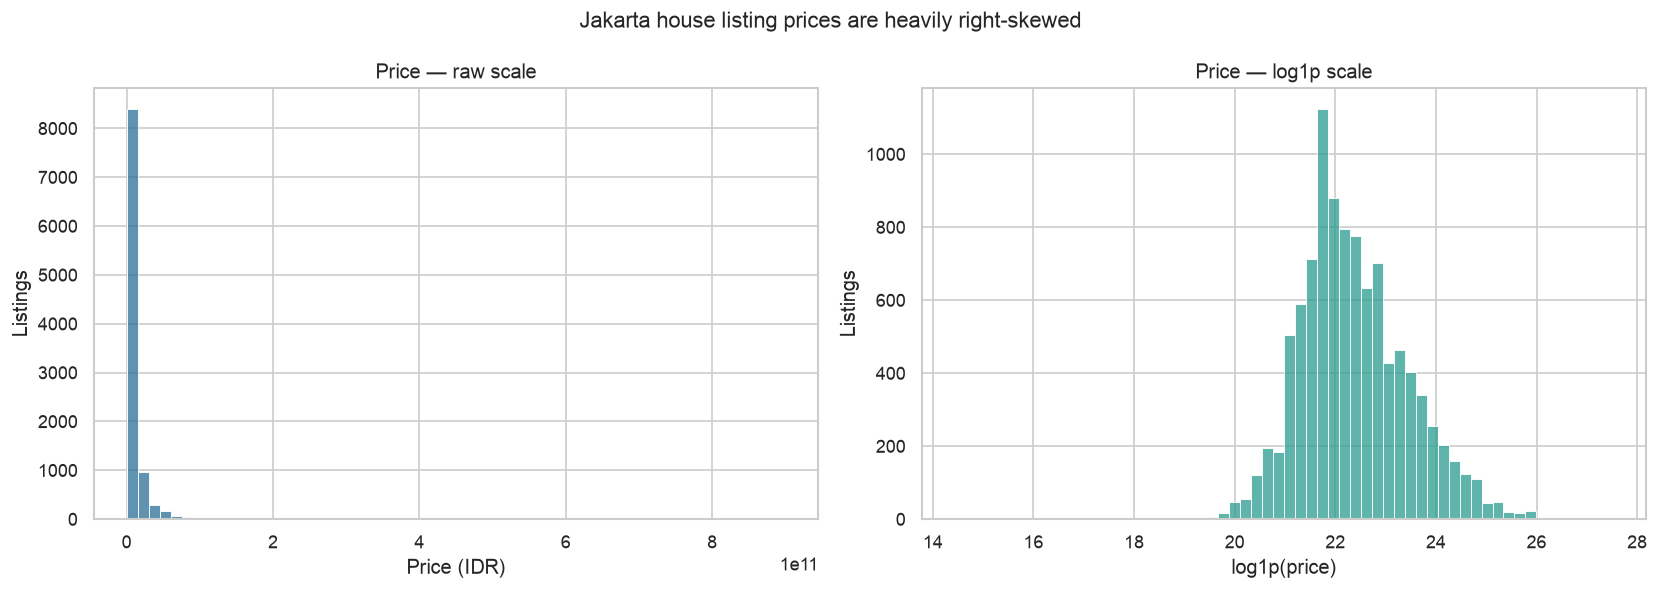

,price_idr
count,1.000000e+04
mean,1.004029e+10
std,2.004519e+10
min,1.850000e+06
1%,5.550000e+08
5%,1.100000e+09
25%,2.500000e+09
50%,4.500000e+09
75%,9.800000e+09
95%,3.600000e+10


Skew raw:   13.664
Skew log1p: 0.214
Skew cleanup removes most of the extreme tail, but log1p is still used for training.


In [4]:
price = raw["price"]
log_price = np.log1p(price)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(price, bins=60, ax=axes[0], color="#2a6f97")
axes[0].set_title("Price — raw scale")
axes[0].set_xlabel("Price (IDR)")
axes[0].set_ylabel("Listings")

sns.histplot(log_price, bins=60, ax=axes[1], color="#2a9d8f")
axes[1].set_title("Price — log1p scale")
axes[1].set_xlabel("log1p(price)")
axes[1].set_ylabel("Listings")

fig.suptitle("Jakarta house listing prices are heavily right-skewed", fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_price_distribution.png", bbox_inches="tight")
plt.show()

stats = price.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).to_frame("price_idr")
display(stats)
print(f"Skew raw:   {price.skew():.3f}")
print(f"Skew log1p: {log_price.skew():.3f}")
print(f"Skew cleanup removes most of the extreme tail, but log1p is still used for training.")

## 3. Geographic coverage and price by city

In [5]:
city_stats = (
    raw.groupby("city")["price"]
    .agg(listings="size", median="median", mean="mean", minimum="min", maximum="max")
    .sort_values("listings", ascending=False)
)
city_stats["share_pct"] = (city_stats["listings"] / len(raw) * 100).round(1)
display(city_stats)

print("\nAll cities:", sorted(raw["city"].unique()))
print("All districts:", raw["district"].nunique())
print("Top 15 districts:")
display(raw["district"].value_counts().head(15).to_frame("listings"))

,listings,median,mean,minimum,maximum,share_pct
city,,,,,,
Jakarta Selatan,3379,8.800000e+09,1.670448e+10,12500000,900000000000,33.8
Jakarta Barat,2622,3.200000e+09,4.523864e+09,7100000,77500000000,26.2
Jakarta Utara,1739,5.450000e+09,8.592813e+09,2300000,85000000000,17.4
Jakarta Timur,1690,2.450000e+09,3.486268e+09,1850000,81000000000,16.9
Jakarta Pusat,570,6.900000e+09,1.975825e+10,116000000,179000000000,5.7



All cities: ['Jakarta Barat', 'Jakarta Pusat', 'Jakarta Selatan', 'Jakarta Timur', 'Jakarta Utara']
All districts: 253
Top 15 districts:


,listings
district,
Kelapa Gading,435
Pondok Indah,393
Pantai Indah Kapuk,364
Tebet,341
Kebayoran Baru,340
Sunter,340
Citra Garden,255
Jagakarsa,242
Cilandak,233


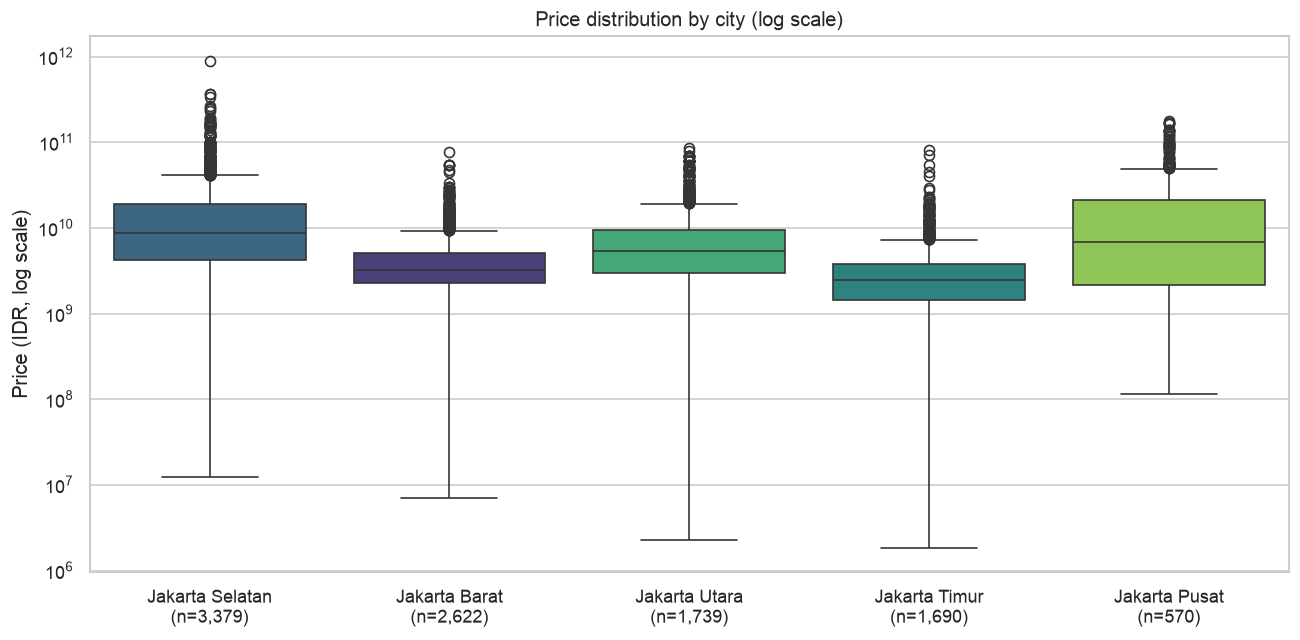

In [6]:
order = raw["city"].value_counts().index
counts = raw["city"].value_counts()

fig, ax = plt.subplots(figsize=(11, 5.5))
sns.boxplot(
    data=raw,
    x="city",
    y="price",
    order=order,
    hue="city",
    palette="viridis",
    legend=False,
    ax=ax,
)
ax.set_yscale("log")
ax.set_title("Price distribution by city (log scale)")
ax.set_xlabel("")
ax.set_ylabel("Price (IDR, log scale)")
ax.set_xticks(range(len(order)))
ax.set_xticklabels([f"{city}\n(n={counts[city]:,})" for city in order])
fig.tight_layout()
fig.savefig(FIG_DIR / "02_price_by_city.png", bbox_inches="tight")
plt.show()

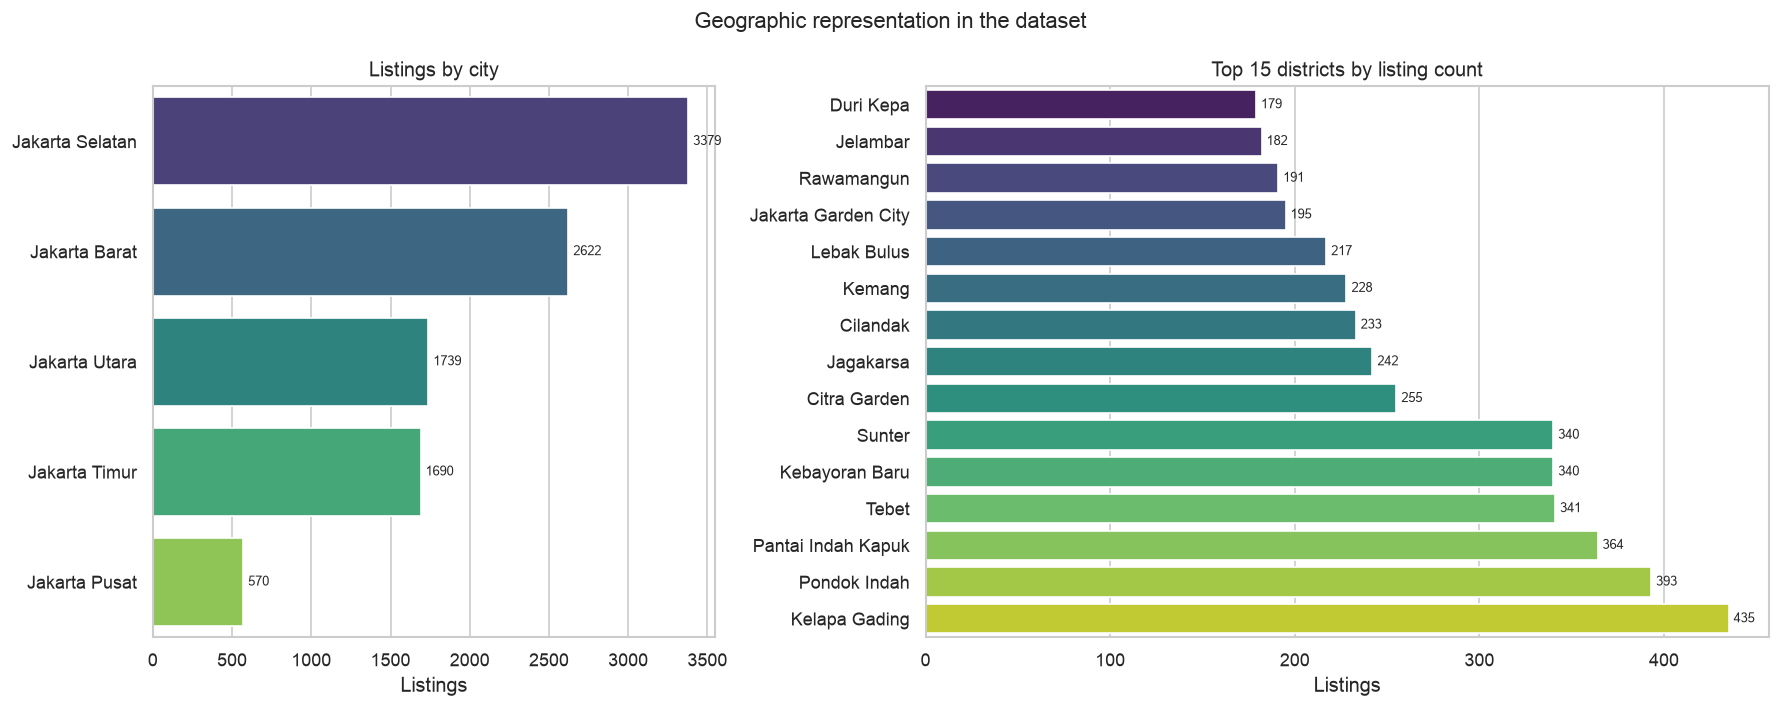

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1.5]})

sns.barplot(
    x=counts.values,
    y=counts.index,
    hue=counts.index,
    palette="viridis",
    legend=False,
    ax=axes[0],
)
axes[0].set_title("Listings by city")
axes[0].set_xlabel("Listings")
axes[0].set_ylabel("")

top_districts = raw["district"].value_counts().head(15).iloc[::-1]
sns.barplot(
    x=top_districts.values,
    y=top_districts.index,
    hue=top_districts.index,
    palette="viridis",
    legend=False,
    ax=axes[1],
)
axes[1].set_title("Top 15 districts by listing count")
axes[1].set_xlabel("Listings")
axes[1].set_ylabel("")

for ax in axes:
    for container in ax.containers:
        ax.bar_label(container, padding=3, fontsize=8)

fig.suptitle("Geographic representation in the dataset", fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_listings_by_location.png", bbox_inches="tight")
plt.show()

## 4. Missing values and duplicates

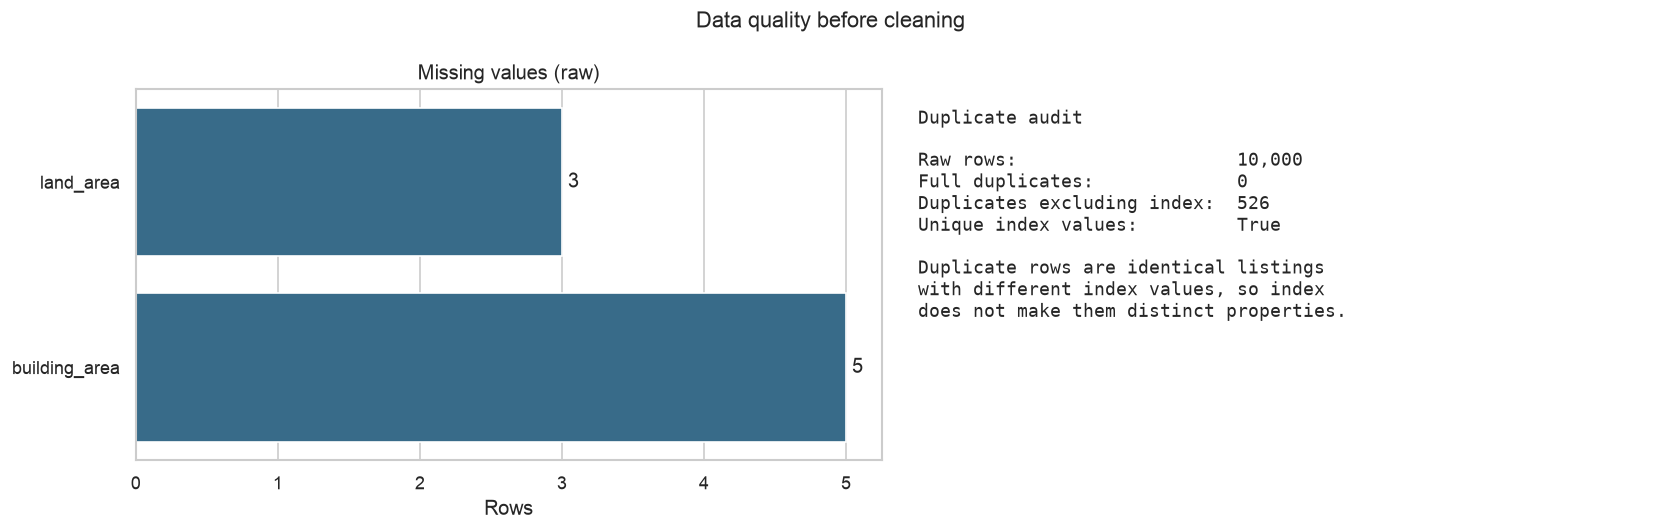

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

missing = raw.isna().sum()
missing = missing[missing > 0].sort_values()
if missing.empty:
    axes[0].text(0.5, 0.5, "No missing values", ha="center", va="center")
    axes[0].axis("off")
else:
    sns.barplot(x=missing.values, y=missing.index, ax=axes[0], color="#2a6f97")
    axes[0].set_title("Missing values (raw)")
    axes[0].set_xlabel("Rows")
    axes[0].set_ylabel("")
    for i, value in enumerate(missing.values):
        axes[0].text(value, i, f" {value}", va="center")

dup_count = int(raw.duplicated(subset=duplicate_columns).sum())
text = (
    "Duplicate audit\n\n"
    f"Raw rows:                    {len(raw):,}\n"
    f"Full duplicates:             {int(raw.duplicated().sum()):,}\n"
    f"Duplicates excluding index:  {dup_count:,}\n"
    f"Unique index values:         {raw['index'].is_unique}\n\n"
    "Duplicate rows are identical listings\n"
    "with different index values, so index\n"
    "does not make them distinct properties."
)
axes[1].axis("off")
axes[1].text(0.02, 0.95, text, va="top", fontsize=10.5, family="monospace")

fig.suptitle("Data quality before cleaning", fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "04_missing_and_duplicates.png", bbox_inches="tight")
plt.show()

## 5. Price drivers: building area, rooms, and carport

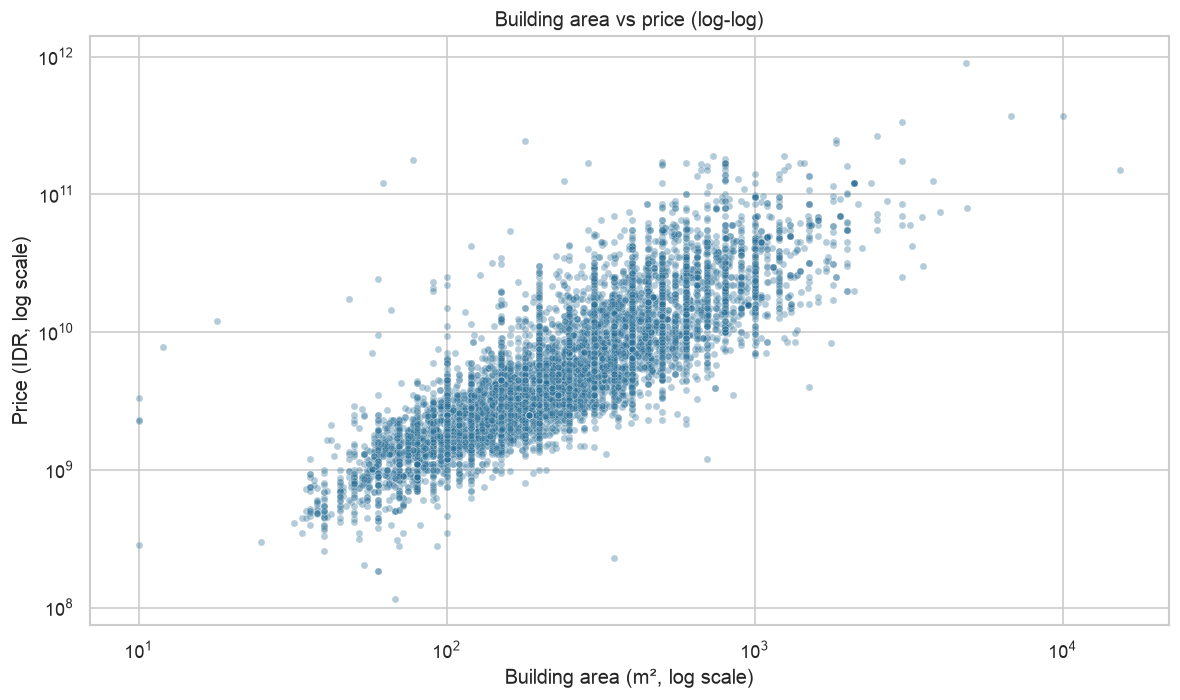

Pearson correlation (building_area, price): 0.625
Spearman correlation (building_area, price): 0.859


In [9]:
plot_df = clean.dropna(subset=["building_area", "price"])

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(
    data=plot_df,
    x="building_area",
    y="price",
    alpha=0.35,
    s=18,
    color="#2a6f97",
    ax=ax,
)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Building area vs price (log-log)")
ax.set_xlabel("Building area (m², log scale)")
ax.set_ylabel("Price (IDR, log scale)")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_building_area_vs_price.png", bbox_inches="tight")
plt.show()

print(f"Pearson correlation (building_area, price): {plot_df['building_area'].corr(plot_df['price']):.3f}")
print(f"Spearman correlation (building_area, price): {plot_df['building_area'].corr(plot_df['price'], method='spearman'):.3f}")

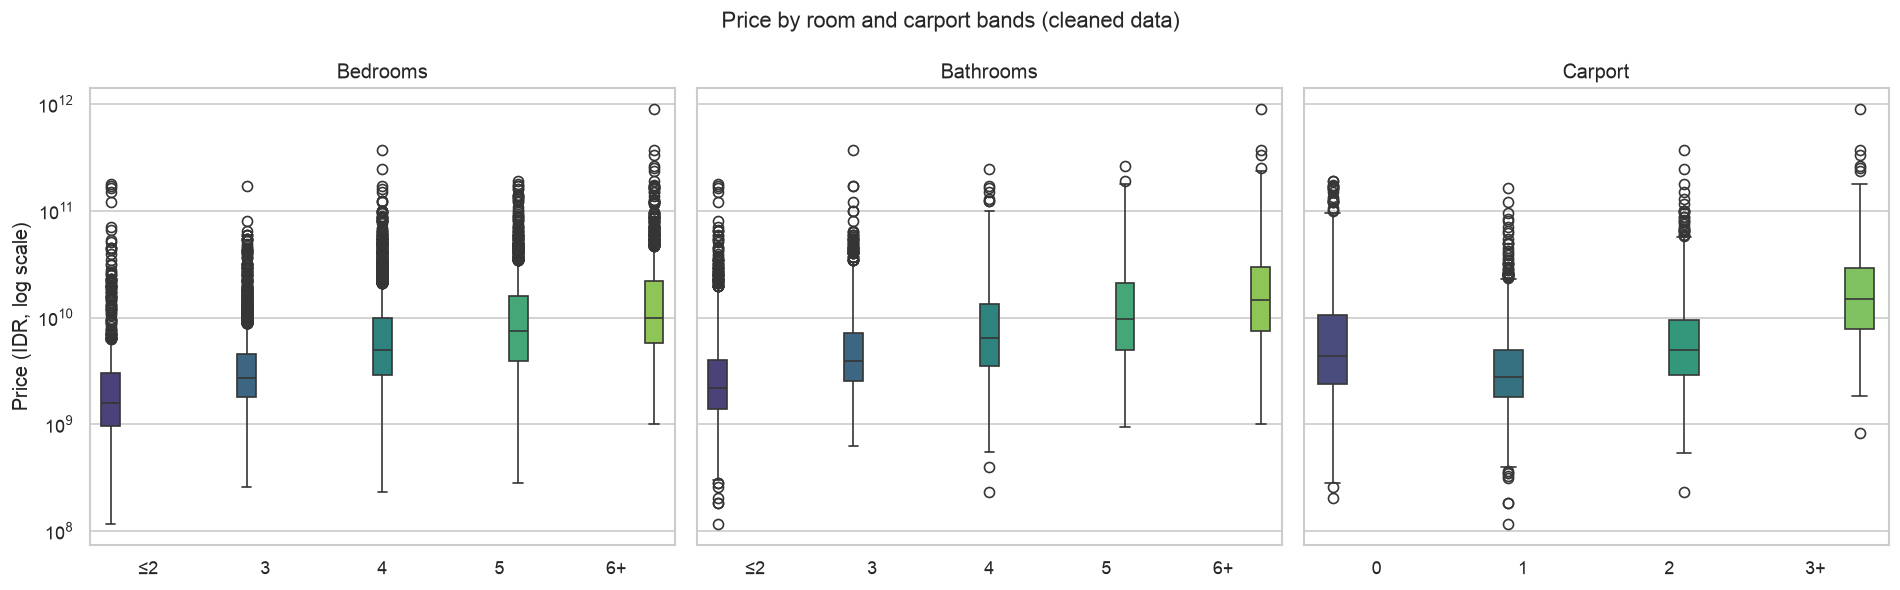

In [10]:
rooms = clean.copy()
rooms["bed_band"] = pd.cut(rooms["bed_rooms"], [-1, 2, 3, 4, 5, np.inf], labels=["≤2", "3", "4", "5", "6+"])
rooms["bath_band"] = pd.cut(rooms["bath_rooms"], [-1, 2, 3, 4, 5, np.inf], labels=["≤2", "3", "4", "5", "6+"])
rooms["carport_band"] = pd.cut(rooms["carport"], [-1, 0, 1, 2, np.inf], labels=["0", "1", "2", "3+"])

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
specs = [
    ("bed_band", "Bedrooms", ["≤2", "3", "4", "5", "6+"]),
    ("bath_band", "Bathrooms", ["≤2", "3", "4", "5", "6+"]),
    ("carport_band", "Carport", ["0", "1", "2", "3+"]),
]

for ax, (column, label, order) in zip(axes, specs):
    sns.boxplot(
        data=rooms,
        x=column,
        y="price",
        order=order,
        hue=column,
        palette="viridis",
        legend=False,
        ax=ax,
    )
    ax.set_yscale("log")
    ax.set_title(label)
    ax.set_xlabel("")
    ax.set_ylabel("Price (IDR, log scale)" if ax is axes[0] else "")

fig.suptitle("Price by room and carport bands (cleaned data)", fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "06_rooms_carport_vs_price.png", bbox_inches="tight")
plt.show()

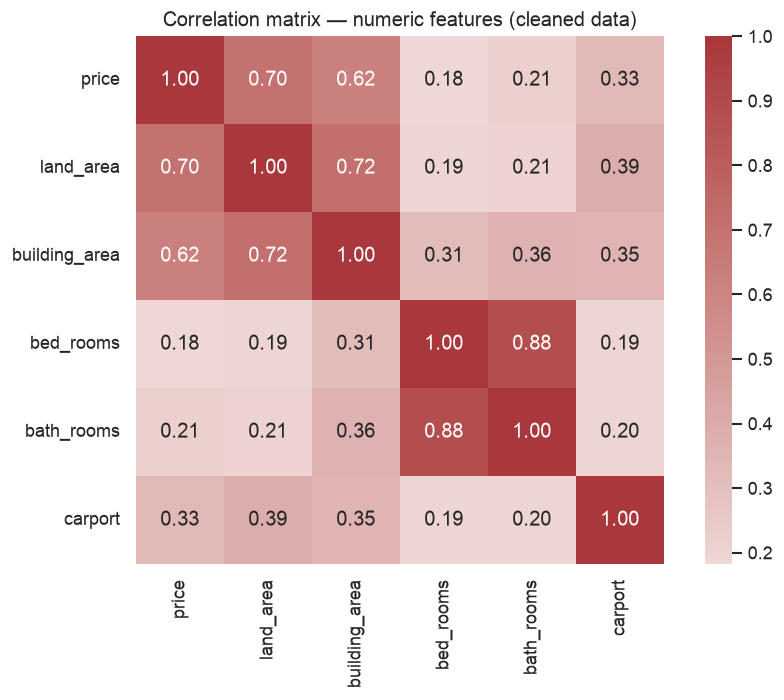

,corr_with_price
price,1.000000
land_area,0.700357
building_area,0.624775
carport,0.330057
bath_rooms,0.212280
bed_rooms,0.182088


In [11]:
numeric_columns = ["price", "land_area", "building_area", "bed_rooms", "bath_rooms", "carport"]
corr = clean[numeric_columns].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True, ax=ax)
ax.set_title("Correlation matrix — numeric features (cleaned data)")
fig.tight_layout()
fig.savefig(FIG_DIR / "07_correlation_heatmap.png", bbox_inches="tight")
plt.show()

display(corr["price"].sort_values(ascending=False).to_frame("corr_with_price"))

## 6. Outliers and plausibility checks

In [12]:
checks = {
    "price <= 0": int((raw["price"] <= 0).sum()),
    "price < Rp100M": int((raw["price"] < 100_000_000).sum()),
    "building_area < 10 m²": int((raw["building_area"] < 10).sum()),
    "building_area missing": int(raw["building_area"].isna().sum()),
    "building_area > land_area": int((raw["building_area"] > raw["land_area"]).sum()),
    "bed_rooms == 0": int((raw["bed_rooms"] == 0).sum()),
    "bath_rooms == 0": int((raw["bath_rooms"] == 0).sum()),
    "carport == 0": int((raw["carport"] == 0).sum()),
    "land_area > 5,000 m²": int((raw["land_area"] > 5_000).sum()),
    "building_area > 5,000 m²": int((raw["building_area"] > 5_000).sum()),
}
display(pd.Series(checks, name="rows").to_frame())

display(
    raw[["price", "building_area", "land_area", "bed_rooms", "bath_rooms", "carport"]]
    .describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99])
    .T
)

,rows
price <= 0,0
price < Rp100M,13
building_area < 10 m²,57
building_area missing,5
building_area > land_area,6687
bed_rooms == 0,198
bath_rooms == 0,198
carport == 0,2354
"land_area > 5,000 m²",11
"building_area > 5,000 m²",3


,count,mean,std,min,1%,5%,50%,95%,99%,max
price,10000.0,1.004029e+10,2.004519e+10,1850000.0,555000000.0,1.100000e+09,4.500000e+09,3.600000e+10,8.500000e+10,9.000000e+11
building_area,9995.0,3.199625e+02,3.576760e+02,1.0,40.0,6.800000e+01,2.300000e+02,8.500000e+02,1.500000e+03,1.533100e+04
land_area,9997.0,2.966102e+02,5.029217e+02,1.0,32.0,5.500000e+01,1.770000e+02,9.000000e+02,1.620240e+03,1.771400e+04
bed_rooms,10000.0,4.253500e+00,3.176609e+00,0.0,0.0,2.000000e+00,4.000000e+00,7.000000e+00,1.600000e+01,6.300000e+01
bath_rooms,10000.0,3.521300e+00,2.900136e+00,0.0,0.0,1.000000e+00,3.000000e+00,6.000000e+00,1.001000e+01,6.300000e+01
carport,10000.0,1.578900e+00,1.743467e+00,0.0,0.0,0.000000e+00,1.000000e+00,4.000000e+00,1.000000e+01,3.100000e+01


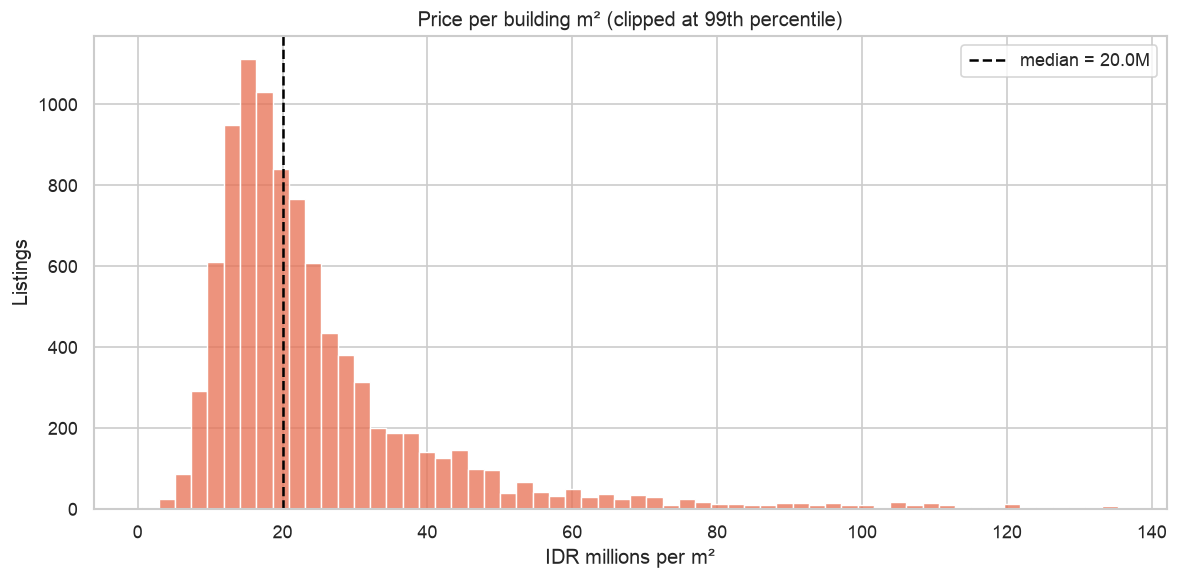

Price per building m² quantiles (IDR):


,idr_per_m2
0.01,7.098765e+06
0.05,1.000000e+07
0.25,1.500000e+07
0.50,2.000000e+07
0.75,2.919708e+07
0.95,6.500000e+07
0.99,1.352941e+08


Top 5 price-per-m² values:


,price,building_area,land_area,city,district,price_per_m2
8725,179000000000,78.0,51.0,Jakarta Pusat,Senen,2.294872e+09
5623,122000000000,62.0,32.0,Jakarta Selatan,Sultan Agung,1.967742e+09
3447,245000000000,180.0,97.0,Jakarta Selatan,Jagakarsa,1.361111e+09
2369,12000000000,18.0,344.0,Jakarta Selatan,Setiabudi,6.666667e+08
2971,7800000000,12.0,300.0,Jakarta Utara,Muara Karang,6.500000e+08


These values are retained: without source-level evidence they cannot be proven invalid.


In [13]:
price_per_m2 = (clean["price"] / clean["building_area"]).replace([np.inf, -np.inf], np.nan).dropna()
upper = price_per_m2.quantile(0.99)

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(price_per_m2[price_per_m2 <= upper] / 1e6, bins=60, color="#e76f51", ax=ax)
ax.axvline(price_per_m2.median() / 1e6, color="black", linestyle="--", label=f"median = {price_per_m2.median()/1e6:.1f}M")
ax.set_title("Price per building m² (clipped at 99th percentile)")
ax.set_xlabel("IDR millions per m²")
ax.set_ylabel("Listings")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "08_price_per_m2_outliers.png", bbox_inches="tight")
plt.show()

print("Price per building m² quantiles (IDR):")
display(price_per_m2.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).to_frame("idr_per_m2"))

print("Top 5 price-per-m² values:")
display(
    (clean.assign(price_per_m2=clean["price"] / clean["building_area"])
     .nlargest(5, "price_per_m2")[["price", "building_area", "land_area", "city", "district", "price_per_m2"]])
)

print("These values are retained: without source-level evidence they cannot be proven invalid.")

## 7. Cleaning impact and final feature contract

,step,rows_before,rows_after,rows_removed,reason
0,drop_duplicate_listings,10000,9474,526,duplikat persis selain index
1,drop_invalid_price,9474,9474,0,"price missing, nol, atau negatif"
2,drop_low_price,9474,9461,13,"price < Rp100,000,000 (tidak masuk akal untuk ..."
3,drop_invalid_building_area,9461,9401,60,building_area missing atau < 10 m2


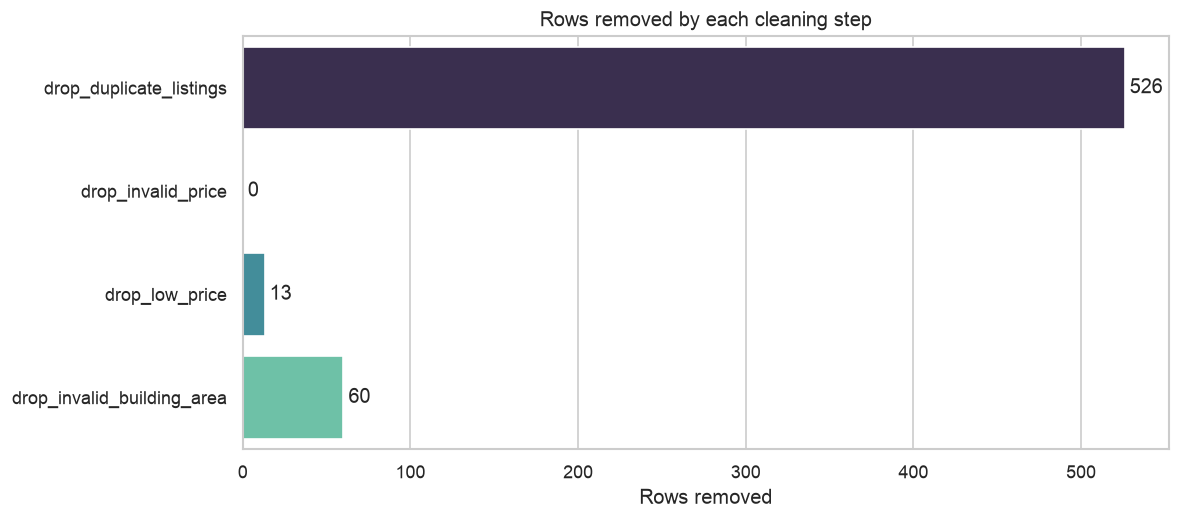

Rows: 10,000 -> 9,401 (599 removed)
Cleaning rules:
  - drop_duplicates: semua kolom kecuali index
  - min_price: 100000000
  - min_building_area: 10
  - zero_rooms: bed_rooms/bath_rooms == 0 dianggap missing
  - carport_zero: dipertahankan (tidak punya carport)
  - high_prices: dipertahankan; target log1p digunakan saat training

Missing values after cleaning:


,missing
bed_rooms,190
bath_rooms,187
land_area,3


Zero rooms masked as missing:


,value
bed_rooms,190
bath_rooms,187
note,diimputasi median di dalam pipeline training


In [14]:
steps = pd.DataFrame(report["steps"])
display(steps)

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=steps, x="rows_removed", y="step", hue="step", palette="mako", legend=False, ax=ax)
ax.set_title("Rows removed by each cleaning step")
ax.set_xlabel("Rows removed")
ax.set_ylabel("")
for container in ax.containers:
    ax.bar_label(container, padding=3)
fig.tight_layout()
fig.savefig(FIG_DIR / "09_cleaning_steps.png", bbox_inches="tight")
plt.show()

print(f"Rows: {report['raw_rows']:,} -> {report['clean_rows']:,} ({report['rows_removed_total']:,} removed)")
print("Cleaning rules:")
for key, value in report["rules"].items():
    print(f"  - {key}: {value}")

print("\nMissing values after cleaning:")
display(clean.isna().sum()[clean.isna().sum() > 0].to_frame("missing"))

print("Zero rooms masked as missing:")
display(pd.Series(report["zero_rooms_masked"], name="value").to_frame())

In [15]:
FEATURES = ["city", "building_area", "bed_rooms", "bath_rooms", "carport"]
TARGET = "price"

print("Model features:", FEATURES)
print("Target:", TARGET)
print("All required columns present:", all(column in clean.columns for column in FEATURES + [TARGET]))
print("Extra columns kept for analysis:", [c for c in clean.columns if c not in FEATURES + [TARGET]])

display(clean[FEATURES + [TARGET]].head())
display(clean[FEATURES + [TARGET]].describe(include="all").T)

Model features: ['city', 'building_area', 'bed_rooms', 'bath_rooms', 'carport']
Target: price
All required columns present: True
Extra columns kept for analysis: ['index', 'district', 'land_area']


,city,building_area,bed_rooms,bath_rooms,carport,price
0,Jakarta Barat,350.0,2.0,4.0,2,5900000000
1,Jakarta Barat,225.0,4.0,2.0,0,2700000000
2,Jakarta Barat,140.0,3.0,3.0,0,2200000000
3,Jakarta Barat,120.0,3.0,2.0,0,1900000000
4,Jakarta Barat,108.0,4.0,3.0,0,2100000000


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
city,9401,5,Jakarta Selatan,3215,NaN,NaN,NaN,NaN,NaN,NaN,NaN
building_area,9401.0,NaN,NaN,NaN,323.678651,362.245458,10.0,140.0,232.0,400.0,15331.0
bed_rooms,9211.0,NaN,NaN,NaN,4.353273,3.156409,1.0,3.0,4.0,5.0,63.0
bath_rooms,9214.0,NaN,NaN,NaN,3.594313,2.872778,1.0,2.0,3.0,4.0,63.0
carport,9401.0,NaN,NaN,NaN,1.579087,1.757218,0.0,1.0,1.0,2.0,31.0
price,9401.0,NaN,NaN,NaN,10166875438.783108,20344779491.124046,116000000.0,2500000000.0,4500000000.0,10000000000.0,900000000000.0


## 8. Findings, cleaning decisions, and limitations

### Cleaning decisions (implemented in `src/data_prep.py`)

1. **Duplicates** — 526 rows are identical listings with different `index` values; they are
   dropped, keeping the first occurrence.
2. **Implausible prices** — 13 listings below Rp100 million are dropped. A house in Jakarta
   cannot realistically be listed at Rp1.85–54 million; these values are consistent with
   scraping/unit errors. Expensive listings are **not** removed.
3. **Invalid building area** — 60 rows with `building_area` missing or below 10 m² are dropped.
   1 m² buildings cannot be valid houses and cannot support a size-based model.
4. **Zero rooms** — `bed_rooms == 0` and `bath_rooms == 0` are treated as missing, then imputed
   with the training median inside the pipeline. `carport == 0` is kept because having no
   carport is a real property attribute.
5. **Land area and district** — kept in the processed CSV for analysis, but not used by the
   first model version. The model contract is exactly five features:
   `city`, `building_area`, `bed_rooms`, `bath_rooms`, `carport`.

### Key findings

- Only **five cities** are present, all in DKI Jakarta; the project must not claim Jabodetabek
  coverage.
- `city` is heavily imbalanced: Jakarta Selatan dominates; Jakarta Pusat has the fewest listings.
- The target spans roughly **Rp116 million to Rp900 billion** after cleaning and is strongly
  right-skewed; `log1p(price)` is used for training and predictions are converted back to IDR.
- `building_area` and `land_area` are the strongest numeric correlates of price; bedroom and
  bathroom counts are correlated with each other (multicollinearity).
- **6,687 raw rows have `building_area > land_area`**, a strong sign of measurement noise.
  This is documented but not corrected, because the direction of the error is unknown.
- Price-per-m² outliers remain after cleaning; they are kept unless there is source-level proof
  of invalidity, and their effect is checked during model evaluation.

### Limitations

- Prices are **listing/asking prices** scraped from Rumah123, not transaction prices.
- The dataset has **no date column**, so market period and inflation effects cannot be modeled.
- No coordinates, street, or property-condition data; `city` is a coarse location signal.
- District has 253 values and is excluded from the baseline to keep the input contract small.
- Scraping artifacts (duplicates, unit errors, area inconsistencies) remain a source of noise.
- The model produces an estimate from historical listing patterns, not an appraisal or a
  guarantee of transaction price.